# SuperTuxKart: DAgger vs SAC with symmetric replay


In [1]:
import os, sys
from pathlib import Path

PROJECT_DIR = Path.home() / "Documents" / "RL" / "Mini project 2"
REPO = PROJECT_DIR / "pystk_project"
assert (REPO / "src/agents/team4/agent4.py").is_file(), "Team 4 repository not found"
sys.path.insert(0, str(REPO / "src"))

scratch = Path(f"/temporary/stk-{os.getuid()}")
scratch.mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(scratch)
runtime = scratch / "runtime"
runtime.mkdir(parents=True, exist_ok=True, mode=0o700)
runtime.chmod(0o700)
os.environ["XDG_RUNTIME_DIR"] = str(runtime)
print("Repository:", REPO)
print("Game assets cached:", (scratch / "PySuperTuxKart2/1.5/__downloaded__.txt").is_file())
print("Scratch:", scratch)


Repository: /users/Etu7/21502067/Documents/RL/Mini project 2/pystk_project
Game assets cached: True
Scratch: /temporary/stk-21502067


In [2]:
import copy, csv, json, math, random, sys
from dataclasses import dataclass, asdict
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Independent, Normal, TanhTransform, TransformedDistribution
import matplotlib.pyplot as plt
import gymnasium as gym
import pystk2_gymnasium
from pystk2_gymnasium import AgentSpec
from scipy import stats
sys.path.insert(0, str(REPO / "src"))
from agents.team4.agent4 import Agent4

@dataclass
class Config:
    env_name: str = "supertuxkart/full-v0"
    max_paths: int = 20
    track: str = "lighthouse"
    steps: int = 300_000
    steps_per_epoch: int = 1_000
    seeds: tuple = (1, 2, 3)
    episode_limit: int = 1_200
    demo_episodes: int = 25
    demo_max_attempts: int = 100
    min_expert_finish_rate: float = 0.70
    batch_size: int = 256
    buffer_size: int = 300_000
    sac_warmup_steps: int = 1_000
    sac_updates_per_step: int = 1
    bc_warmup_updates: int = 1_000
    dagger_updates_per_epoch: int = 150
    eval_interval: int = 10_000
    eval_episodes: int = 5
    final_eval_episodes: int = 20
    lr: float = 3e-4
    gamma: float = 0.99
    tau: float = 0.005
    alpha_initial: float = 0.2
    max_grad_norm: float = 1.0
    hidden: tuple = (256, 256)
    output_dir: str = str(scratch / "stk_results")

cfg = Config()
EXPERT_FILE = str(REPO / "src/agents/team4/agent4.py")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path(cfg.output_dir) / cfg.track
ROOT.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE, "| online steps per method per seed:", cfg.steps)

Device: cuda | online steps per method per seed: 300000


In [3]:
FEATURE_SCALE = {
    "velocity": 30.0, "center_path": 20.0, "center_path_distance": 10.0,
    "max_steer_angle": 1.0, "paths_start": 40.0, "paths_end": 40.0,
    "paths_width": 10.0, "distance_down_track": 500.0,
}

class KartEnv:
    def __init__(self, settings):
        self.settings = settings
        self.env = gym.make(settings.env_name, track=settings.track, num_kart=1, laps=1,
                            max_paths=settings.max_paths, agent=AgentSpec(use_ai=False, name="RL driver"),
                            render_mode=None, disable_env_checker=True)
        self.native_observation_space = self.env.observation_space
        self.native_action_space = self.env.action_space
        example, _ = self.env.reset(seed=0)
        missing = [key for key in FEATURE_SCALE if key not in example]
        if missing:
            self.env.close()
            raise KeyError(f"Missing observation fields in full-v0: {missing}")
        self.feature_sizes = {key: np.asarray(example[key]).size for key in FEATURE_SCALE}
        self.feature_sizes["paths_start"] = settings.max_paths * 3
        self.feature_sizes["paths_end"] = settings.max_paths * 3
        self.feature_sizes["paths_width"] = settings.max_paths
        self.obs_dim = sum(self.feature_sizes.values())
        self.raw_obs = copy.deepcopy(example)
        self.episode_steps = 0

    def encode(self, raw):
        parts = []
        for key, scale in FEATURE_SCALE.items():
            x = np.asarray(raw[key], dtype=np.float32).reshape(-1)
            count = self.feature_sizes[key]
            values = np.zeros(count, dtype=np.float32)
            n = min(count, x.size)
            values[:n] = np.clip(np.nan_to_num(x[:n] / scale, nan=0, posinf=0, neginf=0), -5, 5)
            parts.append(values)
        return np.concatenate(parts)

    def native_action(self, action):
        a = np.clip(np.asarray(action, dtype=np.float32).reshape(2), -1, 1)
        return {"acceleration": float((a[0] + 1) / 2), "steer": float(a[1]),
                "brake": 0, "drift": 0, "nitro": 0, "rescue": 0, "fire": 0}

    def reset(self, seed=None):
        raw, info = self.env.reset(seed=seed)
        self.raw_obs = copy.deepcopy(raw)
        self.episode_steps = 0
        return self.encode(self.raw_obs), info

    def step(self, action):
        previous_distance = float(np.asarray(self.raw_obs["distance_down_track"]).reshape(-1)[0])
        raw, _, terminated, truncated, info = self.env.step(self.native_action(action))
        self.episode_steps += 1
        if self.episode_steps >= self.settings.episode_limit and not terminated:
            truncated = True
        finished = bool(terminated and not truncated)
        current = float(np.asarray(raw["distance_down_track"]).reshape(-1)[0])
        current_distance = float(info.get("distance", current)) if finished else current
        progress = float(np.clip(current_distance - previous_distance, -5, 10))
        reward = progress - 0.1 + (100.0 if finished else 0.0)
        self.raw_obs = copy.deepcopy(raw)
        result_info = dict(info)
        result_info["finished_lap"] = finished
        result_info["progress_m"] = progress
        return self.encode(self.raw_obs), reward, bool(terminated), bool(truncated), result_info

    def close(self):
        self.env.close()

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def new_reset(env, rng):
    return env.reset(seed=int(rng.integers(0, 2**31 - 1)))[0]

probe = KartEnv(cfg)
try:
    observation, _ = probe.reset(seed=1)
    print("Environment:", cfg.env_name, "| track:", cfg.track, "| max_paths:", cfg.max_paths)
    print("Observation dimension:", observation.shape[0])
    print("Continuous controls:", probe.native_action(np.array([1.0, 0.0], np.float32)))
finally:
    probe.close()


Environment: supertuxkart/full-v0 | track: lighthouse | max_paths: 20
Observation dimension: 149
Continuous controls: {'acceleration': 1.0, 'steer': 0.0, 'brake': 0, 'drift': 0, 'nitro': 0, 'rescue': 0, 'fire': 0}


In [4]:
class Expert:
    def __init__(self, env, file=None):
        self.env = env
        self.name = "team4"
        if not file or not Path(file).is_file():
            raise FileNotFoundError(f"Team 4 agent file not found: {file}")
        self.reset()

    def reset(self):
        self.driver = Agent4(self.env.env)

    def act(self, raw):
        obs = dict(raw)
        obs.setdefault("powerup_type", 0)
        obs.setdefault("powerup_count", 0)
        native = self.driver.choose_action(obs)
        acceleration = float(np.asarray(native["acceleration"]).reshape(-1)[0])
        steer = float(np.asarray(native["steer"]).reshape(-1)[0])
        return np.clip([2.0 * acceleration - 1.0, steer], -1, 1).astype(np.float32)

def save_rows(path, rows, fields):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)

def load_rows(path):
    with Path(path).open(newline="") as f:
        return list(csv.DictReader(f))

def demonstrations(settings):
    folder = ROOT / "demonstrations"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / "expert_transitions.npz"
    metadata_path = folder / "metadata.json"
    if path.exists() and metadata_path.exists():
        previous = json.loads(metadata_path.read_text())
        if (previous.get("expert_file") == str(EXPERT_FILE)
                and previous.get("track") == settings.track
                and previous.get("features") == FEATURE_SCALE
                and previous.get("demo_episodes") == settings.demo_episodes
                and previous.get("env_name") == settings.env_name
                and previous.get("max_paths") == settings.max_paths
                and previous.get("action_space") == "acceleration_steer_only"):

            saved = np.load(path)
            print("Loaded existing expert transitions:", len(saved["obs"]))
            return {k: saved[k] for k in saved.files}
        print("Expert settings changed: rebuilding demonstration dataset")
    env = KartEnv(settings)
    expert = Expert(env, EXPERT_FILE)
    storage = {k: [] for k in ("obs", "action", "reward", "next_obs", "terminated")}
    attempts, successes, attempts_log = 0, 0, []
    try:
        while successes < settings.demo_episodes and attempts < settings.demo_max_attempts:
            attempts += 1
            expert.reset()
            obs, _ = env.reset(seed=100_000 + attempts)
            trajectory = {k: [] for k in storage}
            total_reward, finished = 0.0, False
            for step in range(settings.episode_limit):
                action = expert.act(env.raw_obs)
                next_obs, reward, terminated, truncated, info = env.step(action)
                for k, v in zip(storage, (obs, action, reward, next_obs, terminated)):
                    trajectory[k].append(v)
                total_reward += reward
                obs = next_obs
                if terminated or truncated:
                    finished = info["finished_lap"]
                    break
            successes += int(finished)
            attempts_log.append(dict(attempt=attempts, steps=step + 1, return_=total_reward,
                                     finished=int(finished)))
            if finished:
                for k in storage:
                    storage[k].extend(trajectory[k])
            print(f"Expert episode {attempts:03d} | complete={int(finished)} | "
                  f"successful={successes}/{settings.demo_episodes} | steps={step+1}")
        save_rows(folder / "expert_episodes.csv", attempts_log, ["attempt", "steps", "return_", "finished"])
        if not successes:
            raise RuntimeError("The expert completed no laps. Provide a stronger EXPERT_FILE and rerun.")
        finish_rate = successes / attempts
        if finish_rate < settings.min_expert_finish_rate:
            print(f"WARNING: expert completion rate {finish_rate:.0%} is below "
                  f"{settings.min_expert_finish_rate:.0%}; consider a stronger expert before reporting results.")
        arrays = {k: np.asarray(v, dtype=np.float32) for k, v in storage.items()}
        np.savez_compressed(path, **arrays)
        metadata_path.write_text(json.dumps(dict(expert=expert.name, expert_file=str(EXPERT_FILE),
            attempts=attempts, completions=successes, success_rate=finish_rate,
            transitions=len(arrays["obs"]), track=settings.track, features=FEATURE_SCALE,
            demo_episodes=settings.demo_episodes, online_budget_not_including_demos=True,
            env_name=settings.env_name, max_paths=settings.max_paths,
            action_space="acceleration_steer_only"), indent=2))
        print(f"Saved {len(arrays['obs']):,} expert transitions | expert completion rate {finish_rate:.1%}")
        return arrays
    finally:
        env.close()

def check_expert_lap(settings, seed=42):
    env = KartEnv(settings)
    teacher = Expert(env, EXPERT_FILE)
    try:
        obs, _ = env.reset(seed=seed)
        teacher.reset()
        finished = False
        for step in range(1, settings.episode_limit + 1):
            action = teacher.act(env.raw_obs)
            obs, _, terminated, truncated, info = env.step(action)
            if step % 100 == 0 or terminated or truncated:
                print(f"Expert check: {step} steps | distance={float(np.asarray(env.raw_obs['distance_down_track']).reshape(-1)[0]):.1f} | finished={info['finished_lap']}")
            if terminated or truncated:
                finished = info["finished_lap"]
                break
        if not finished:
            raise RuntimeError("Expert did not finish with the two-action interface. Don't start training; the native controls need adapting.")
        print(f"Expert completes a lap using only acceleration and steering: {step} steps")
    finally:
        env.close()

check_expert_lap(cfg)
expert_data = demonstrations(cfg)
test_env = KartEnv(cfg)
test_expert = Expert(test_env, EXPERT_FILE)
try:
    test_env.reset(seed=42)
    sample_action = test_expert.act(test_env.raw_obs)
    print("Team 4 action:", sample_action)
    print("Native kart action:", test_env.native_action(sample_action))
    obs, reward, terminated, truncated, info = test_env.step(sample_action)
    print("Step OK | reward:", round(reward, 3), "| terminated:", terminated)
finally:
    test_env.close()


Expert check: 100 steps | distance=153.9 | finished=False
Expert check: 200 steps | distance=384.8 | finished=False
Expert check: 300 steps | distance=615.5 | finished=False
Expert check: 400 steps | distance=846.5 | finished=False
Expert check: 415 steps | distance=0.9 | finished=True
Expert completes a lap using only acceleration and steering: 415 steps
Loaded existing expert transitions: 10375
Team 4 action: [1. 0.]
Native kart action: {'acceleration': 1.0, 'steer': 0.0, 'brake': 0, 'drift': 0, 'nitro': 0, 'rescue': 0, 'fire': 0}
Step OK | reward: -0.1 | terminated: False


In [5]:
def build_mlp(sizes, last_activation=False):
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2 or last_activation:
            layers.append(nn.ReLU())
    return nn.Sequential(*layers)

class SquashedGaussianActor(nn.Module):
    def __init__(self, obs_dim, hidden, action_dim=2, min_std=1e-4):
        super().__init__()
        self.backbone = build_mlp([obs_dim, *hidden], last_activation=True)
        self.mean_layer = nn.Linear(hidden[-1], action_dim)
        self.std_layer = nn.Linear(hidden[-1], action_dim)
        self.softplus = nn.Softplus()
        self.min_std = min_std
        self.tanh = TanhTransform(cache_size=1)

    def dist(self, obs):
        features = self.backbone(obs)
        mean = self.mean_layer(features)
        std = self.softplus(self.std_layer(features)) + self.min_std
        return TransformedDistribution(Independent(Normal(mean, std), 1), [self.tanh])

    def forward(self, obs):
        dist = self.dist(obs)
        action = dist.rsample()
        log_prob = dist.log_prob(action)
        self.tanh._cached_x_y = (None, None)
        return action, log_prob

    def act(self, obs):
        return torch.tanh(self.mean_layer(self.backbone(obs)))

class ContinuousQNetwork(nn.Module):
    def __init__(self, obs_dim, hidden, action_dim=2):
        super().__init__()
        self.model = build_mlp([obs_dim + action_dim, *hidden, 1])

    def forward(self, obs, action):
        return self.model(torch.cat([obs, action], dim=1)).squeeze(-1)

@torch.no_grad()
def soft_update(source, target, tau):
    for param, target_param in zip(source.parameters(), target.parameters()):
        target_param.lerp_(param, tau)

class ReplayBuffer:
    def __init__(self, capacity, obs_dim):
        self.capacity = capacity
        self.obs = np.empty((capacity, obs_dim), dtype=np.float32)
        self.action = np.empty((capacity, 2), dtype=np.float32)
        self.reward = np.empty(capacity, dtype=np.float32)
        self.next_obs = np.empty((capacity, obs_dim), dtype=np.float32)
        self.terminated = np.empty(capacity, dtype=np.float32)
        self.size, self.index = 0, 0

    def add(self, obs, action, reward, next_obs, terminated):
        i = self.index
        self.obs[i], self.action[i] = obs, action
        self.reward[i], self.next_obs[i], self.terminated[i] = reward, next_obs, float(terminated)
        self.index = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, count, rng):
        idx = rng.integers(self.size, size=count)
        return [getattr(self, k)[idx] for k in ("obs", "action", "reward", "next_obs", "terminated")]

    def save(self, path):
        np.savez_compressed(path, **{k: getattr(self, k)[:self.size]
            for k in ("obs", "action", "reward", "next_obs", "terminated")})

def tensor_batch(arrays):
    return [torch.as_tensor(x, dtype=torch.float32, device=DEVICE) for x in arrays]

def balanced_batch(offline, online, size, rng):
    n_off = size // 2
    n_on = size - n_off
    indices = rng.integers(len(offline["obs"]), size=n_off)
    first = [offline[k][indices] for k in ("obs", "action", "reward", "next_obs", "terminated")]
    second = online.sample(n_on, rng)
    return tensor_batch([np.concatenate([a, b]) for a, b in zip(first, second)])

def compute_critic_loss(gamma, alpha, batch, actor, critics, target_critics):
    obs, action, reward, next_obs, terminated = batch
    with torch.no_grad():
        next_action, next_logp = actor(next_obs)
        q_next = torch.minimum(target_critics[0](next_obs, next_action),
                               target_critics[1](next_obs, next_action))
        target = reward + gamma * (1.0 - terminated) * (q_next - alpha * next_logp)
    pred_q1 = critics[0](obs, action)
    pred_q2 = critics[1](obs, action)
    return F.mse_loss(pred_q1, target) + F.mse_loss(pred_q2, target)

def compute_actor_loss(alpha, obs, actor, critics):
    action, log_prob = actor(obs)
    q = torch.minimum(critics[0](obs, action), critics[1](obs, action))
    return (alpha * log_prob - q).mean(), log_prob

In [6]:
def choose_action(actor, obs, stochastic=False):
    x = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)
    with torch.no_grad():
        action = actor(x)[0] if stochastic else actor.act(x)
    return action[0].cpu().numpy().astype(np.float32)

def evaluate(env, actor, episodes, seed_base):
    records = []
    for i in range(episodes):
        obs, _ = env.reset(seed=seed_base + i)
        total, finished = 0.0, False
        for step in range(env.settings.episode_limit):
            obs, reward, terminated, truncated, info = env.step(choose_action(actor, obs))
            total += reward
            if terminated or truncated:
                finished = info["finished_lap"]
                break
        records.append(dict(episode=i, finished=int(finished), lap_steps=step+1 if finished else np.nan,
                            episode_steps=step+1, return_=total))
    laps = [r["lap_steps"] for r in records if r["finished"]]
    summary = dict(finish_rate=np.mean([r["finished"] for r in records]),
                   lap_steps=np.mean(laps) if laps else np.nan,
                   eval_return=np.mean([r["return_"] for r in records]))
    return summary, records

def write_config(folder, settings, method, seed):
    folder.mkdir(parents=True, exist_ok=True)
    metadata = asdict(settings) | {"method":method, "seed":seed, "features":FEATURE_SCALE,
        "action": "[normalized_acceleration, steer]", "reward":"delta_distance_down_track - 0.1 + 100*finish",
        "comparison": "DAgger vs SAC 50/50 balanced replay", "expert_file":str(EXPERT_FILE),
        "torch_version":torch.__version__, "numpy_version":np.__version__,
        "pystk2_gymnasium_version":__import__("importlib.metadata", fromlist=["version"]).version("pystk2-gymnasium")}
    (folder / "config.json").write_text(json.dumps(metadata, indent=2))

def save_training(folder, episodes, evaluations, losses):
    save_rows(folder / "train_episodes.csv", episodes,
              ["step", "episode", "return_", "length", "finished"])
    save_rows(folder / "evaluations.csv", evaluations,
              ["step", "finish_rate", "lap_steps", "eval_return"])
    save_rows(folder / "updates.csv", losses,
              ["step", "actor_loss", "critic_loss", "alpha"])

def score_eval(metrics):
    return (metrics["finish_rate"],
            -metrics["lap_steps"] if np.isfinite(metrics["lap_steps"]) else -1e9,
            metrics["eval_return"])

def progress(method, seed, step, epoch, settings, last_evaluation, finished_episodes):
    recent = finished_episodes[-10:]
    mean_return = np.mean([x["return_"] for x in recent]) if recent else float("nan")
    rate = np.mean([x["finished"] for x in recent]) if recent else float("nan")
    eval_string = (f"eval={last_evaluation['finish_rate']:.0%}" if last_evaluation else "eval=not yet")
    print(f"{method:6s} seed={seed} | epoch {epoch:03d}/{math.ceil(settings.steps/settings.steps_per_epoch):03d} "
          f"| steps {step:,}/{settings.steps:,} | train_return={mean_return:7.1f} "
          f"| completed={rate:4.0%} | {eval_string}", flush=True)

## DAgger: aggregate learner states and relabel with the expert

In [12]:
def bc_updates(actor, optimizer, observations, actions, count, batch_size, rng, max_grad):
    actor.train()
    final_loss = float("nan")
    for _ in range(count):
        idx = rng.integers(len(observations), size=batch_size)
        x = torch.as_tensor(observations[idx], device=DEVICE)
        y = torch.as_tensor(actions[idx], device=DEVICE)
        loss = F.mse_loss(actor.act(x), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(actor.parameters(), max_grad)
        optimizer.step()
        final_loss = float(loss.item())
    return final_loss

def train_dagger(settings, offline, seed):
    seed_everything(seed)
    rng = np.random.default_rng(seed)
    folder = ROOT / f"dagger_seed{seed}"
    write_config(folder, settings, "dagger", seed)
    env = KartEnv(settings)
    expert = Expert(env, EXPERT_FILE)
    actor = SquashedGaussianActor(env.obs_dim, settings.hidden).to(DEVICE)
    optimizer = torch.optim.Adam(actor.parameters(), lr=settings.lr)
    n_initial = len(offline["obs"])
    labels_obs = np.empty((n_initial + settings.steps, env.obs_dim), dtype=np.float32)
    labels_act = np.empty((n_initial + settings.steps, 2), dtype=np.float32)
    labels_obs[:n_initial] = offline["obs"]
    labels_act[:n_initial] = offline["action"]
    n_labels = n_initial
    episodes, evaluations, updates = [], [], []
    bc_updates(actor, optimizer, labels_obs[:n_labels], labels_act[:n_labels],
               settings.bc_warmup_updates, settings.batch_size, rng, settings.max_grad_norm)
    total_reward, episode_len, episode_num = 0.0, 0, 0
    recent_eval, best = None, None
    next_eval = settings.eval_interval
    try:
        expert.reset()
        obs = new_reset(env, rng)
        for step in range(1, settings.steps + 1):
            labels_obs[n_labels] = obs
            labels_act[n_labels] = expert.act(env.raw_obs)
            n_labels += 1
            action = choose_action(actor, obs)
            next_obs, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            episode_len += 1
            obs = next_obs
            if terminated or truncated:
                episode_num += 1
                episodes.append(dict(step=step, episode=episode_num, return_=total_reward,
                                     length=episode_len, finished=int(info["finished_lap"])))
                total_reward, episode_len = 0.0, 0
                expert.reset()
                obs = new_reset(env, rng)
            if step % settings.steps_per_epoch == 0 or step == settings.steps:
                loss = bc_updates(actor, optimizer, labels_obs[:n_labels], labels_act[:n_labels],
                                  settings.dagger_updates_per_epoch, settings.batch_size,
                                  rng, settings.max_grad_norm)
                updates.append(dict(step=step, actor_loss=loss, critic_loss=np.nan, alpha=np.nan))
                epoch = math.ceil(step / settings.steps_per_epoch)
                progress("DAgger", seed, step, epoch, settings, recent_eval, episodes)
                save_training(folder, episodes, evaluations, updates)
                if epoch % 10 == 0 or step == settings.steps:
                    torch.save(actor.state_dict(), folder / "policy_latest.pt")
            if (terminated or truncated or step == settings.steps) and step >= next_eval:
                recent_eval, _ = evaluate(env, actor, settings.eval_episodes, 1_000_000)
                evaluations.append(dict(step=step, **recent_eval))
                if best is None or score_eval(recent_eval) > best:
                    best = score_eval(recent_eval)
                    torch.save(actor.state_dict(), folder / "policy_best.pt")
                next_eval = step + settings.eval_interval
                expert.reset()
                if step < settings.steps:
                    obs = new_reset(env, rng)
        final, records = evaluate(env, actor, settings.final_eval_episodes, 2_000_000)
        save_rows(folder / "final_eval_episodes.csv", records,
                  ["episode", "finished", "lap_steps", "episode_steps", "return_"])
        save_training(folder, episodes, evaluations, updates)
        np.savez_compressed(folder / "dagger_labels.npz", obs=labels_obs[:n_labels], action=labels_act[:n_labels])
        torch.save(actor.state_dict(), folder / "policy_final.pt")
        print("DAgger final:", final)
        return final
    finally:
        env.close()

## SAC with symmetric replay (50% offline, 50% online)

In [13]:
def train_balanced_sac(settings, offline, seed):
    seed_everything(seed)
    rng = np.random.default_rng(seed)
    folder = ROOT / f"balanced_sac_seed{seed}"
    write_config(folder, settings, "balanced_sac", seed)
    env = KartEnv(settings)
    actor = SquashedGaussianActor(env.obs_dim, settings.hidden).to(DEVICE)
    critics = (ContinuousQNetwork(env.obs_dim, settings.hidden).to(DEVICE),
               ContinuousQNetwork(env.obs_dim, settings.hidden).to(DEVICE))
    targets = tuple(copy.deepcopy(c) for c in critics)
    actor_optimizer = torch.optim.Adam(actor.parameters(), lr=settings.lr)
    critic_optimizer = torch.optim.Adam(list(critics[0].parameters()) +
                                        list(critics[1].parameters()), lr=settings.lr)
    log_alpha = torch.tensor(math.log(settings.alpha_initial), dtype=torch.float32,
                             device=DEVICE, requires_grad=True)
    alpha_optimizer = torch.optim.Adam([log_alpha], lr=settings.lr)
    target_entropy = -2.0
    online = ReplayBuffer(settings.buffer_size, env.obs_dim)
    episodes, evaluations, updates = [], [], []
    total_reward, episode_len, episode_num = 0.0, 0, 0
    recent_eval, best = None, None
    last_actor_loss, last_critic_loss = float("nan"), float("nan")
    next_eval = settings.eval_interval
    try:
        obs = new_reset(env, rng)
        for step in range(1, settings.steps + 1):
            action = (rng.uniform(-1, 1, size=2).astype(np.float32)
                      if step <= settings.sac_warmup_steps else choose_action(actor, obs, stochastic=True))
            next_obs, reward, terminated, truncated, info = env.step(action)
            online.add(obs, action, reward, next_obs, terminated)
            obs = next_obs
            total_reward += reward
            episode_len += 1
            if online.size >= max(settings.sac_warmup_steps, settings.batch_size // 2):
                for _ in range(settings.sac_updates_per_step):
                    batch = balanced_batch(offline, online, settings.batch_size, rng)
                    alpha = float(log_alpha.detach().exp().item())
                    critic_loss = compute_critic_loss(settings.gamma, alpha, batch,
                                                      actor, critics, targets)
                    critic_optimizer.zero_grad(set_to_none=True)
                    critic_loss.backward()
                    torch.nn.utils.clip_grad_norm_(list(critics[0].parameters()) +
                        list(critics[1].parameters()), settings.max_grad_norm)
                    critic_optimizer.step()
                    for c in critics:
                        for p in c.parameters():
                            p.requires_grad_(False)
                    actor_loss, log_prob = compute_actor_loss(alpha, batch[0], actor, critics)
                    actor_optimizer.zero_grad(set_to_none=True)
                    actor_loss.backward()
                    torch.nn.utils.clip_grad_norm_(actor.parameters(), settings.max_grad_norm)
                    actor_optimizer.step()
                    for c in critics:
                        for p in c.parameters():
                            p.requires_grad_(True)
                    alpha_loss = -(log_alpha * (log_prob.detach() + target_entropy)).mean()
                    alpha_optimizer.zero_grad(set_to_none=True)
                    alpha_loss.backward()
                    alpha_optimizer.step()
                    for c, t in zip(critics, targets):
                        soft_update(c, t, settings.tau)
                    last_actor_loss = float(actor_loss.item())
                    last_critic_loss = float(critic_loss.item())
            if terminated or truncated:
                episode_num += 1
                episodes.append(dict(step=step, episode=episode_num, return_=total_reward,
                                     length=episode_len, finished=int(info["finished_lap"])))
                total_reward, episode_len = 0.0, 0
                obs = new_reset(env, rng)
            if step % settings.steps_per_epoch == 0 or step == settings.steps:
                updates.append(dict(step=step, actor_loss=last_actor_loss,
                                    critic_loss=last_critic_loss, alpha=float(log_alpha.exp().item())))
                epoch = math.ceil(step / settings.steps_per_epoch)
                progress("SAC50%", seed, step, epoch, settings, recent_eval, episodes)
                save_training(folder, episodes, evaluations, updates)
                if epoch % 10 == 0 or step == settings.steps:
                    torch.save(actor.state_dict(), folder / "policy_latest.pt")
            if (terminated or truncated or step == settings.steps) and step >= next_eval:
                recent_eval, _ = evaluate(env, actor, settings.eval_episodes, 1_000_000)
                evaluations.append(dict(step=step, **recent_eval))
                if best is None or score_eval(recent_eval) > best:
                    best = score_eval(recent_eval)
                    torch.save(actor.state_dict(), folder / "policy_best.pt")
                next_eval = step + settings.eval_interval
                if step < settings.steps:
                    obs = new_reset(env, rng)
        final, records = evaluate(env, actor, settings.final_eval_episodes, 2_000_000)
        save_rows(folder / "final_eval_episodes.csv", records,
                  ["episode", "finished", "lap_steps", "episode_steps", "return_"])
        save_training(folder, episodes, evaluations, updates)
        online.save(folder / "online_replay.npz")
        torch.save(actor.state_dict(), folder / "policy_final.pt")
        print("Balanced SAC final:", final)
        return final
    finally:
        env.close()

## Run the study

In [13]:
summary_file = ROOT / "summary.csv"
summary_rows = load_rows(summary_file) if summary_file.exists() else []

for seed in cfg.seeds:
    for method, trainer in [
        ("dagger", train_dagger),
        ("balanced_sac", train_balanced_sac)
    ]:
        already_done = any(
            row["method"] == method and int(row["seed"]) == seed
            for row in summary_rows
        )

        if already_done:
            print(f"{method} seed {seed} already completed")
            continue

        print(f"\n=== {method} | seed {seed} | {cfg.steps:,} steps ===")

        result = trainer(cfg, expert_data, seed)
        summary_rows.append(dict(method=method, seed=seed, **result))

        save_rows(
            summary_file,
            summary_rows,
            ["method", "seed", "finish_rate", "lap_steps", "eval_return"]
        )

print("Training finished. Results saved in", ROOT)


=== DAgger | seed 1 | 300,000 steps ===
DAgger seed=1 | epoch 001/300 | steps 1,000/300,000 | train_return=  939.4 | completed=100% | eval=not yet
DAgger seed=1 | epoch 002/300 | steps 2,000/300,000 | train_return=  939.2 | completed=100% | eval=not yet
DAgger seed=1 | epoch 003/300 | steps 3,000/300,000 | train_return=  939.0 | completed=100% | eval=not yet
DAgger seed=1 | epoch 004/300 | steps 4,000/300,000 | train_return=  938.9 | completed=100% | eval=not yet
DAgger seed=1 | epoch 005/300 | steps 5,000/300,000 | train_return=  938.8 | completed=100% | eval=not yet
DAgger seed=1 | epoch 006/300 | steps 6,000/300,000 | train_return=  938.7 | completed=100% | eval=not yet
DAgger seed=1 | epoch 007/300 | steps 7,000/300,000 | train_return=  938.8 | completed=100% | eval=not yet
DAgger seed=1 | epoch 008/300 | steps 8,000/300,000 | train_return=  938.8 | completed=100% | eval=not yet
DAgger seed=1 | epoch 009/300 | steps 9,000/300,000 | train_return=  939.0 | completed=100% | eval=not 

## Matplotlib curves and confidence intervals

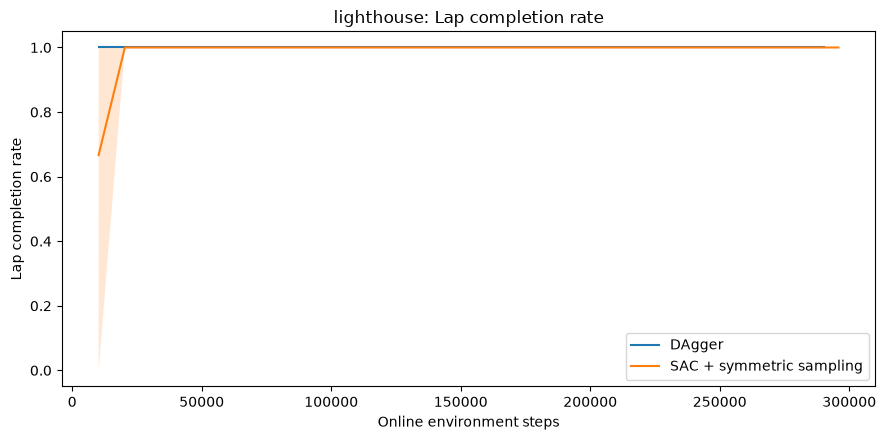

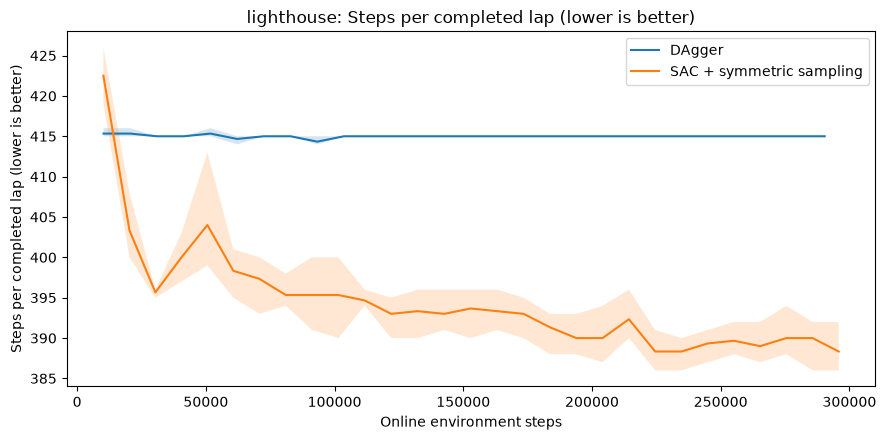

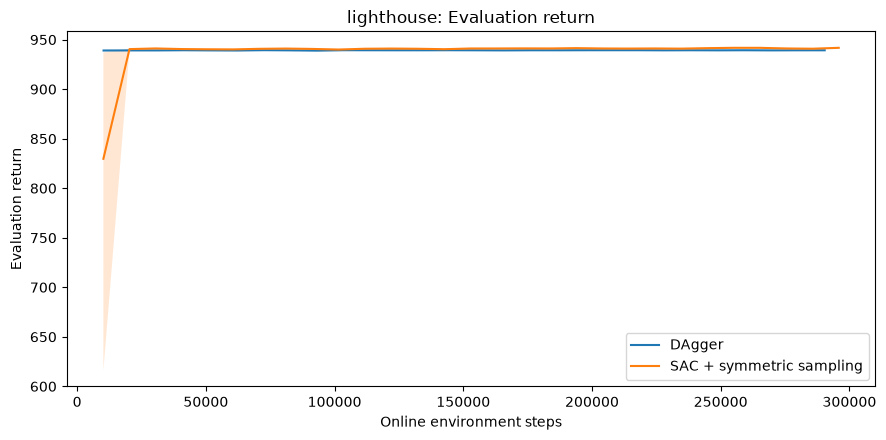

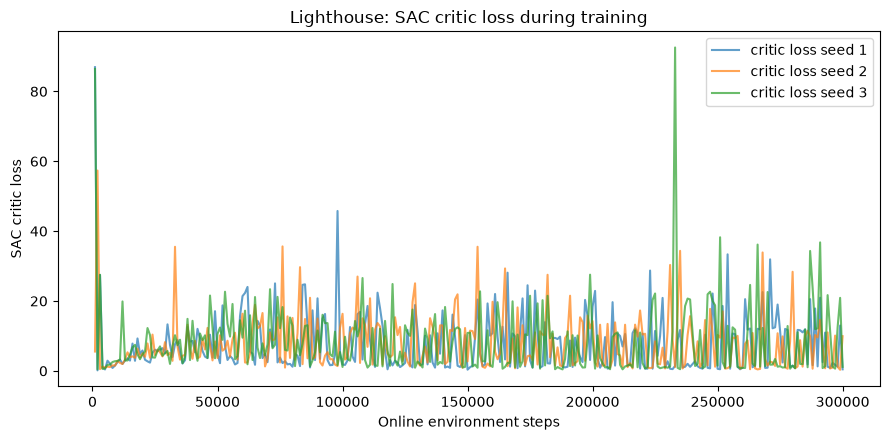

In [7]:
def bootstrap_mean_ci(values, n=4_000, seed=42):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    means = values[rng.integers(len(values), size=(n, len(values)))].mean(axis=1)
    return float(np.mean(values)), *np.percentile(means, [2.5, 97.5])

def plot_learning(settings):
    methods = ("dagger", "balanced_sac")
    labels = ("DAgger", "SAC + symmetric sampling")
    for metric, ylabel, filename in (("finish_rate", "Lap completion rate", "finish_rate.png"),
                                    ("lap_steps", "Steps per completed lap (lower is better)", "lap_steps.png"),
                                    ("eval_return", "Evaluation return", "eval_reward.png")):
        plt.figure(figsize=(9, 4.5))
        for method, label in zip(methods, labels):
            curves = {}
            for seed in settings.seeds:
                path = ROOT / f"{method}_seed{seed}" / "evaluations.csv"
                if path.exists():
                    for i, row in enumerate(load_rows(path)):
                        curves.setdefault(i, []).append((float(row["step"]), float(row[metric])))
            if not curves:
                continue
            ix = sorted(curves)
            steps = [np.mean([v[0] for v in curves[i]]) for i in ix]
            bounds = np.asarray([bootstrap_mean_ci([v[1] for v in curves[i]]) for i in ix])
            plt.plot(steps, bounds[:, 0], label=label)
            plt.fill_between(steps, bounds[:, 1], bounds[:, 2], alpha=0.18)
        plt.xlabel("Online environment steps")
        plt.ylabel(ylabel)
        plt.title(f"{settings.track}: {ylabel}")
        plt.legend()
        plt.tight_layout()
        plt.savefig(ROOT / filename, dpi=150)
        plt.show()
    plt.figure(figsize=(9, 4.5))
    for seed in settings.seeds:
        path = ROOT / f"balanced_sac_seed{seed}" / "updates.csv"
        if path.exists():
            rows = load_rows(path)
            plt.plot([float(r["step"]) for r in rows], [float(r["critic_loss"]) for r in rows],
                     alpha=0.7, label=f"critic loss seed {seed}")
    plt.xlabel("Online environment steps")
    plt.ylabel("SAC critic loss")
    plt.title("Lighthouse: SAC critic loss during training")
    plt.legend()
    plt.tight_layout()
    plt.savefig(ROOT / "sac_critic_loss.png", dpi=150)
    plt.show()

plot_learning(cfg)

## Final held-out comparison

In [8]:
summary_path = ROOT / "summary.csv"
if not summary_path.exists():
    raise FileNotFoundError("Run the training cell first; final metrics are not fabricated.")
summary = load_rows(summary_path)
for method in ("dagger", "balanced_sac"):
    rows = [r for r in summary if r["method"] == method]
    print("\n", method, f"({len(rows)} training seeds)")
    for key in ("finish_rate", "lap_steps", "eval_return"):
        mean, lo, hi = bootstrap_mean_ci([float(r[key]) for r in rows])
        print(f"  {key}: {mean:.3f} (bootstrap 95% CI [{lo:.3f}, {hi:.3f}])")

pairs = {int(r["seed"]):r for r in summary if r["method"] == "dagger"}
diffs = []
for row in summary:
    if row["method"] == "balanced_sac" and int(row["seed"]) in pairs:
        diffs.append(float(row["finish_rate"]) - float(pairs[int(row["seed"])]["finish_rate"]))
if len(diffs) >= 2:
    mean, lo, hi = bootstrap_mean_ci(diffs)
    print(f"\nPaired seed difference (SAC50% minus DAgger completion): "
          f"{mean:+.3f} [95% bootstrap {lo:+.3f}, {hi:+.3f}]")



 dagger (3 training seeds)
  finish_rate: 1.000 (bootstrap 95% CI [1.000, 1.000])
  lap_steps: 415.000 (bootstrap 95% CI [415.000, 415.000])
  eval_return: 939.203 (bootstrap 95% CI [939.163, 939.264])

 balanced_sac (3 training seeds)
  finish_rate: 1.000 (bootstrap 95% CI [1.000, 1.000])
  lap_steps: 387.667 (bootstrap 95% CI [385.000, 390.000])
  eval_return: 941.884 (bootstrap 95% CI [941.830, 941.990])

Paired seed difference (SAC50% minus DAgger completion): +0.000 [95% bootstrap +0.000, +0.000]


In [9]:
summary = load_rows(ROOT / "summary.csv")

dagger = {int(r["seed"]): r for r in summary if r["method"] == "dagger"}
sac = {int(r["seed"]): r for r in summary if r["method"] == "balanced_sac"}

seeds = sorted(set(dagger) & set(sac))

d_finish = np.array([float(dagger[s]["finish_rate"]) for s in seeds])
s_finish = np.array([float(sac[s]["finish_rate"]) for s in seeds])

d_steps = np.array([float(dagger[s]["lap_steps"]) for s in seeds])
s_steps = np.array([float(sac[s]["lap_steps"]) for s in seeds])

d_return = np.array([float(dagger[s]["eval_return"]) for s in seeds])
s_return = np.array([float(sac[s]["eval_return"]) for s in seeds])
saved_steps = [
    float(dagger[s]["lap_steps"]) - float(sac[s]["lap_steps"])
    for s in seeds
]

return_gain = [
    float(sac[s]["eval_return"]) - float(dagger[s]["eval_return"])
    for s in seeds
]

for name, values in [
    ("Steps saved per lap by SAC", saved_steps),
    ("Evaluation return gain for SAC", return_gain)
]:
    mean, low, high = bootstrap_mean_ci(values)
    print(f"{name}: {mean:.3f} (95% CI [{low:.3f}, {high:.3f}])")

print(f"Compared using seeds: {seeds}")


Steps saved per lap by SAC: 27.333 (95% CI [25.000, 30.000])
Evaluation return gain for SAC: 2.680 (95% CI [2.566, 2.827])
Compared using seeds: [1, 2, 3]


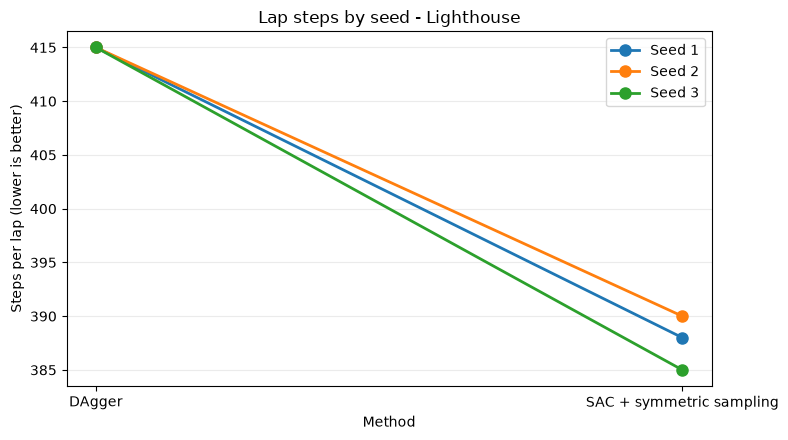

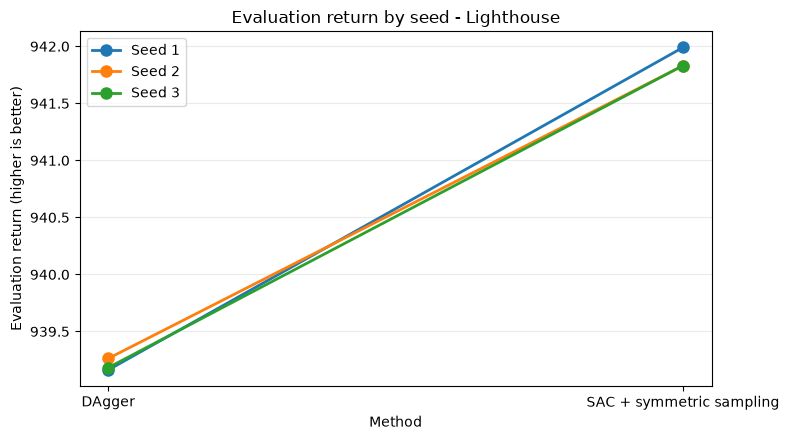

NameError: name 'steps_saved' is not defined

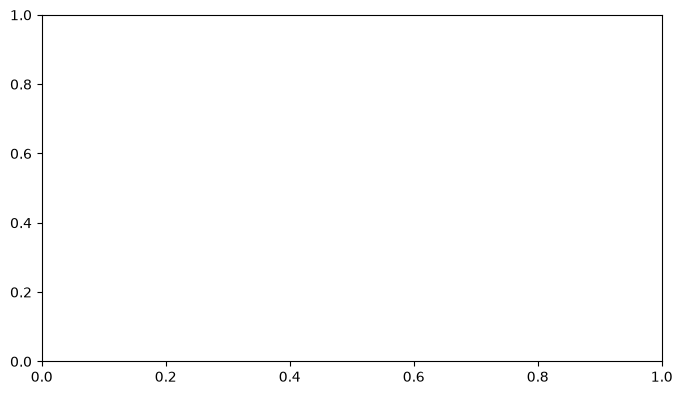

In [10]:
for title, ylabel, filename, d, s in [
    ("Lap steps by seed", "Steps per lap (lower is better)",
     "comparison_lap_steps.png", d_steps, s_steps),
    ("Evaluation return by seed", "Evaluation return (higher is better)",
     "comparison_returns.png", d_return, s_return)
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))

    for i, seed in enumerate(seeds):
        ax.plot([0, 1], [d[i], s[i]], marker="o",
                linewidth=2, markersize=8, label=f"Seed {seed}")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["DAgger", "SAC + symmetric sampling"])
    ax.set_xlabel("Method")
    ax.set_ylabel(ylabel)
    ax.set_title(title + " - Lighthouse")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(ROOT / filename, dpi=150)
    plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar([str(s) for s in seeds], steps_saved)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Training seed")
ax.set_ylabel("DAgger steps - SAC steps")
ax.set_title("Steps saved per lap by SAC")
fig.tight_layout()
fig.savefig(ROOT / "comparison_steps_saved.png", dpi=150)
plt.show()


In [16]:
if np.isclose(d_finish.mean(), s_finish.mean()):
    print("Reliability: Tie. Both methods have the same completion rate.")
else:
    better = "SAC" if s_finish.mean() > d_finish.mean() else "DAgger"
    print("Reliability:", better, "achieves a higher completion rate.")

if s_steps.mean() < d_steps.mean():
    print(f"Speed: SAC is better by {np.mean(saved_steps):.2f} steps per lap.")
else:
    print("Speed: DAgger is faster.")

if s_return.mean() > d_return.mean():
    print(f"Reward: SAC achieves {return_gain.mean():.2f} more return on average.")
else:
    print("Reward: DAgger achieves a higher return.")

Reliability: Tie. Both methods have the same completion rate.
Speed: SAC is better by 27.33 steps per lap.


AttributeError: 'list' object has no attribute 'mean'